# Explore the metadata

**Question:** how was the screen set up and imaged, and how many cells does each well hold? We answer this before we look at the profiles.

This notebook shows three things:

- where each control, ligand and compound (and its dose) sits on the plate.
- how the microscope imaged the plates.
- how many cells each well holds.

Cell number matters because crowded cells look different (smaller, rounder). So an uneven plate adds differences that have nothing to do with treatment. Notebook 01 tests how much cell number changes the profiles. Notebook 04 tests which treatments lower cell number.

Sections: 1. load the well tables, 2. screen design, 3. imaging, 4. cell counts on the plates, 5. DMSO control wells.

Terms used below:

- **Field of view:** one position imaged in a well (9 per well, in a 3 × 3 grid). The microscope images each field of view in 5 channels.
- **All cells:** every cell found in the 9 fields of view of a well, before quality control (QC).
- **QC-passing cells:** cells that passed both image QC (sharp, not saturated) and profile QC (no segmentation errors). The well profiles are the median of these cells.
- **log2 ratio:** log2(cells in the well / median cells in the DMSO wells of the same plate and cell line). 0 = like DMSO, −1 = half as many cells, +1 = twice as many.

## Setup

In [1]:
import os

# limit threads, because this can run on a shared login node
os.environ["POLARS_MAX_THREADS"] = "8"
os.environ["OMP_NUM_THREADS"] = "8"
os.environ["OPENBLAS_NUM_THREADS"] = "8"

import json
import pathlib

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, Normalize, TwoSlopeNorm
from matplotlib.patches import Patch, Rectangle
from PIL import Image
from scipy import ndimage as ndi
from scipy import stats

In [2]:
# inputs: well tables from the preprocessing module, single-cell QC labels, the layout files, and the imaging records
preprocess_results = pathlib.Path("../2.preprocessing/results")
all_cells_path = (preprocess_results / "agg_norm_fs_Panc1_hPSC_well-profiles.parquet").resolve(strict=True)
qced_path = (preprocess_results / "qced_agg_norm_fs_Panc1_hPSC_well-profiles.parquet").resolve(strict=True)
sc_qc_path = pathlib.Path("../1.quality-control/results/qc_Panc1_hPSC_sc-profiles.parquet").resolve(strict=True)
metadata_dir = pathlib.Path("../../data/metadata").resolve(strict=True)
# one folder per plate, with the microscope settings (parameters.json) and the position and time of every image (coords.jsonl)
imaging_dir = pathlib.Path("../../data/sc-profiles/PALS-screen-profiles-v2").resolve(strict=True)
images_dir = pathlib.Path("../../../../project-data/PALS-screen-data").resolve(strict=True)

# outputs
fig_dir = pathlib.Path("results/figures/02.explore-metadata").resolve()
table_dir = pathlib.Path("results/tables/02.explore-metadata").resolve()
fig_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

# fixed order and colors, the same in every notebook (checked for color-blind readers)
plate_order = ["1h", "4h", "24h"]
line_order = ["CL1", "CL2"]
line_colors = {"CL1": "#6250d6", "CL2": "#eda100"}
plate_colors = {"1h": "#2a78d6", "4h": "#eb6834", "24h": "#1baf7a"}
# one color per agent for the plate layout; the dose is shown by shade and label
agent_colors = {
    "DMSO": "#e3e3e3", "CBK041498": "#2a78d6", "CBK175924": "#eb6834", "CBK200566": "#1baf7a",
    "CBK600005": "#6250d6", "CBK600008": "#eda100", "IL6": "#e34948", "TGFb1": "#0d366b",
}
# laser line of each channel and the stain it images (from the image file names)
channel_stain = {"405": "DNA", "488": "RNA", "561": "AGP", "638": "Mito", "730": "ER"}
blues = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#2a78d6", "#0d366b"])
div_cmap = plt.get_cmap("RdBu_r")

# plate geometry
plate_rows = list("ABCDEFGHIJKLMNOP")
n_rows, n_cols = 16, 24
corner_wells = ["A01", "A24", "P01", "P24"]

# treatments: ligands first (TGFb1 = positive control), then compounds
compounds = ["CBK041498", "CBK175924", "CBK200566", "CBK600005", "CBK600008"]
treatment_order = ["TGFb1", "IL6", *compounds]
dose_level = {"L": 0, "M": 1, "H": 2, "0.2": 0, "0.67": 1, "2.0": 2}
# what the dose labels mean: compound stock concentration, or final ligand concentration
dose_text = {"0.2": "0.2 mM", "0.67": "0.67 mM", "2.0": "2 mM", "L": "2.5 ng/ml", "M": "5 ng/ml", "H": "10 ng/ml"}

# figure style for print: figure sizes are the size on paper (7.2 in = full page width), text is 6-9 pt
sns.set_theme(style="ticks")
plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.family": "sans-serif", "font.sans-serif": ["Liberation Sans", "DejaVu Sans"],
    "font.size": 7, "axes.titlesize": 8, "axes.labelsize": 7, "xtick.labelsize": 6, "ytick.labelsize": 6,
    "legend.fontsize": 6.5, "legend.title_fontsize": 7, "figure.titlesize": 9,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "pdf.fonttype": 42,
})
pl.Config.set_tbl_rows(50)
pl.Config.set_tbl_cols(-1)
pl.Config.set_fmt_str_lengths(60)


def save_fig(fig, name):
    """Save a figure as PNG (300 dpi) and PDF, then show it."""
    fig.savefig(fig_dir / f"{name}.png")
    fig.savefig(fig_dir / f"{name}.pdf")
    plt.show()


def plate_array(df, value):
    """Arrange one value per well into a 16 x 24 plate grid (NaN where there is no well)."""
    grid = np.full((n_rows, n_cols), np.nan)
    grid[df["row_idx"].to_numpy(), df["col_idx"].to_numpy()] = df[value].to_numpy()
    return grid


def draw_plate(ax, grid, cmap, norm, title, treated=None, flagged=None):
    """Draw one plate map, with the CL1 | CL2 split, crossed-out corners, and optional dots on treated wells."""
    cmap = cmap.copy()
    cmap.set_bad("#f0f0f0")
    im = ax.imshow(grid, cmap=cmap, norm=norm, aspect="equal", interpolation="none")
    ax.axvline(11.5, color="black", lw=1.2)
    ax.set_xticks(range(n_cols), labels=[str(i) if i % 2 == 1 else "" for i in range(1, n_cols + 1)], fontsize=5)
    ax.set_yticks(range(n_rows), labels=plate_rows, fontsize=5)
    ax.tick_params(length=0, pad=1)
    ax.spines[:].set_visible(False)
    for r, c in [(0, 0), (0, 23), (15, 0), (15, 23)]:
        ax.text(c, r, "×", ha="center", va="center", fontsize=5, color="#888888")
    if treated is not None:
        r, c = np.nonzero(treated)
        ax.scatter(c, r, s=0.8, color="black", marker="o", linewidths=0)
    if flagged is not None:
        # black frame = well fails well QC (its profile is not used)
        for r, c in zip(*np.nonzero(flagged)):
            ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, edgecolor="black", lw=0.9))
    ax.set_title(title, loc="left")
    return im

## 1. Load the well tables

We read three inputs, and join them into one table with one row per well:

1. the cell counts of the all-cells well table.
2. the cell counts of the QC-passing well table.
3. the QC labels of every single cell (only 4 small columns of the large single-cell file).

**Pass if:** both well tables have the same 1,140 wells, and the single-cell file gives the same cell totals.

In [3]:
meta_cols = [
    "Metadata_Plate", "Metadata_Well", "Metadata_Row", "Metadata_Column", "Metadata_cell_line",
    "Metadata_time_point", "Metadata_treatment", "Metadata_well_type", "Metadata_compound_stock_mM",
    "Metadata_ligand_dose", "Metadata_Perturbation", "Metadata_CellCount", "Metadata_SiteCount",
    "Metadata_well_qc", "Metadata_well_qc_reason",
]
well_keys = ["Metadata_Plate", "Metadata_Well"]

all_cells = (
    pl.read_parquet(all_cells_path, columns=meta_cols)
    .with_columns(pl.col(pl.Categorical).cast(pl.String))
    .rename({
        "Metadata_CellCount": "n_cells_all", "Metadata_SiteCount": "n_sites_all",
        "Metadata_well_qc": "well_qc_all", "Metadata_well_qc_reason": "well_qc_reason_all",
    })
)
qced = (
    pl.read_parquet(qced_path, columns=[*well_keys, "Metadata_CellCount", "Metadata_SiteCount", "Metadata_well_qc", "Metadata_well_qc_reason"])
    .with_columns(pl.col(pl.Categorical).cast(pl.String))
    .sort(well_keys)
)

# single-cell QC labels: lazy scan of 4 columns, counted per well, so the 54 GB file is never loaded
sc_counts = (
    pl.scan_parquet(sc_qc_path)
    .select([*well_keys, "Metadata_image_qc", "Metadata_profile_qc"])
    .group_by(well_keys)
    .agg(
        n_cells_sc=pl.len(),
        n_fail_image=(pl.col("Metadata_image_qc") == "fail").sum(),
        n_fail_profile_only=((pl.col("Metadata_image_qc") == "pass") & (pl.col("Metadata_profile_qc") == "fail")).sum(),
    )
    .collect()
    .with_columns(pl.col(pl.Categorical).cast(pl.String))
)

wells = (
    qced.rename({
        "Metadata_CellCount": "n_cells_qc", "Metadata_SiteCount": "n_sites_qc",
        "Metadata_well_qc": "well_qc", "Metadata_well_qc_reason": "well_qc_reason",
    })
    .join(all_cells, on=well_keys, how="left", maintain_order="left")
    .join(sc_counts, on=well_keys, how="left", maintain_order="left")
    .with_columns(
        time_point=pl.col("Metadata_time_point"),
        cell_line=pl.col("Metadata_cell_line"),
        row_idx=pl.col("Metadata_Row").map_elements(plate_rows.index, return_dtype=pl.Int64),
        col_idx=pl.col("Metadata_Column").cast(pl.Int64) - 1,
        pct_pass=100 * pl.col("n_cells_qc") / pl.col("n_cells_all"),
        is_dmso=pl.col("Metadata_treatment") == "DMSO",
        # wells that fail well QC keep their counts, but their profiles are not used downstream
        profile_ok=pl.col("well_qc") == "pass",
        # dose label: L/M/H for ligands, stock mM for compounds
        dose=pl.when(pl.col("Metadata_well_type") == "ligand")
        .then(pl.col("Metadata_ligand_dose"))
        .otherwise(pl.col("Metadata_compound_stock_mM").cast(pl.String)),
    )
)

# checks: same wells in both tables, and the cell totals agree with the single-cell file
assert wells.height == all_cells.height == 1140
assert wells["n_cells_all"].null_count() == 0
assert (wells["n_cells_sc"] == wells["n_cells_all"]).all()
assert (wells["n_cells_qc"] == wells["n_cells_all"] - wells["n_fail_image"] - wells["n_fail_profile_only"]).all()
assert set(corner_wells).isdisjoint(wells["Metadata_Well"].to_list())

print(f"{wells.height:,} wells")
print(f"all cells: {wells['n_cells_all'].sum():,}; QC-passing cells: {wells['n_cells_qc'].sum():,} ({100 * wells['n_cells_qc'].sum() / wells['n_cells_all'].sum():.1f}%)")
print(f"wells with fewer than 9 images with cells (all cells): {(wells['n_sites_all'] < 9).sum()}; after QC: {(wells['n_sites_qc'] < 9).sum()}")
wells.group_by("time_point", "cell_line").agg(
    wells=pl.len(), dmso_wells=pl.col("is_dmso").sum(), all_cells=pl.col("n_cells_all").sum(), qc_cells=pl.col("n_cells_qc").sum(),
).sort(pl.col("time_point").cast(pl.Enum(plate_order)), "cell_line")

1,140 wells
all cells: 2,647,721; QC-passing cells: 2,185,564 (82.5%)
wells with fewer than 9 images with cells (all cells): 3; after QC: 99


time_point,cell_line,wells,dmso_wells,all_cells,qc_cells
str,str,u32,u32,i64,i64
"""1h""","""CL1""",190,127,437353,347653
"""1h""","""CL2""",190,127,348879,310293
"""4h""","""CL1""",190,127,445903,340595
"""4h""","""CL2""",190,127,411720,361923
"""24h""","""CL1""",190,127,359875,263097
"""24h""","""CL2""",190,127,643991,562003


In [4]:
# well QC from preprocessing: a well fails with < 100 cells or > 10% missing values
# (all-cells table: counts all cells; QCed table: counts QC-passing cells)
print(f"wells failing well QC: all-cells table {(wells['well_qc_all'] == 'fail').sum()}, QCed table {(~wells['profile_ok']).sum()}")
failing_wells = (
    wells.filter((pl.col("well_qc") == "fail") | (pl.col("well_qc_all") == "fail"))
    .select("time_point", "cell_line", "Metadata_Well", "Metadata_Perturbation", "n_cells_all", "n_cells_qc", "well_qc_all", "well_qc", "well_qc_reason")
    .sort(pl.col("time_point").cast(pl.Enum(plate_order)), "cell_line", "Metadata_Well")
)
failing_wells.write_csv(table_dir / "well-qc_failing-wells.csv")
failing_wells

wells failing well QC: all-cells table 0, QCed table 4


time_point,cell_line,Metadata_Well,Metadata_Perturbation,n_cells_all,n_cells_qc,well_qc_all,well_qc,well_qc_reason
str,str,str,str,i64,i64,str,str,str
"""24h""","""CL1""","""L04""","""DMSO""",1504,89,"""pass""","""fail""","""fewer than 100 cells"""
"""24h""","""CL1""","""N03""","""CBK175924_0.67""",797,76,"""pass""","""fail""","""fewer than 100 cells"""
"""24h""","""CL1""","""N08""","""CBK175924_2.0""",1009,62,"""pass""","""fail""","""fewer than 100 cells"""
"""24h""","""CL1""","""N10""","""DMSO""",1235,39,"""pass""","""fail""","""fewer than 100 cells"""


**Result: PASS.**

- The data hold 1,140 wells: 190 per cell line per plate, of which 127 are DMSO. The two well tables and the single-cell file agree on the cell count of every well.
- The wells hold 2,647,721 cells in total. 2,185,564 cells (82.5%) pass QC.
- Well QC: no well fails on all cells. 4 wells fail on QC-passing cells (fewer than 100). All 4 are on the 24h plate in CL1: L04 (DMSO, 89 cells), N03 (CBK175924_0.67, 76), N08 (CBK175924_2.0, 62) and N10 (DMSO, 39).
- These 4 wells stay in the cell count maps below. The other notebooks leave out their profiles.
- Only 3 wells have an image with no cells at all (24h plate, CL1: M04, N09, N12). They sit inside the low-count area of section 4. After QC, 99 wells have lost at least one whole image to image QC.

## 2. Screen design

All three plates follow one plate map. Columns 1–12 hold cell line CL1, and columns 13–24 hold CL2.

- Every well received 1,500 nL from the compound plate. This is DMSO alone, or one of 5 compounds at a stock concentration of 0.2, 0.67 or 2 mM.
- Ligand wells received DMSO from the compound plate, plus 50, 100 or 200 nL of TGFβ1 or IL6. This gives a final 2.5, 5 or 10 ng/ml.

We read the two layout files and check them against the profiles.

**Pass if:** the layout files agree with the profiles on every plate. Every treatment and dose has 3 wells per cell line, spread over the plate.

In [5]:
# the two layout files: the compound plate map (one map for all 3 plates) and the ligand file
platemap = pl.read_csv(metadata_dir / "platemap.csv").select(
    pl.col("Well").alias("Metadata_Well"),
    pl.col("Compound ID").alias("compound"),
    pl.col("Conc mM").round(2).alias("compound_stock_mM"),
    pl.col("volume nL").alias("compound_volume_nL"),
)
ligand_file = (
    # the file has empty spacer columns and a dose key on the side; keep the 5 columns we need
    pl.read_csv(metadata_dir / "ligands.csv", columns=[0, 1, 2, 5, 6])
    .pipe(lambda df: df.rename(dict(zip(df.columns, ["well", "ligand_cell_line", "ligand", "ligand_dose", "ligand_volume_nL"]))))
    .filter(pl.col("well").is_not_null())
    .with_columns(
        # A4 -> A04, the well names of the profiles
        Metadata_Well=pl.col("well").str.slice(0, 1) + pl.col("well").str.slice(1).str.zfill(2),
        ligand_dose=pl.col("ligand_dose").str.strip_chars(),
    )
    .drop("well")
)

# the layout as the profiles record it, for each plate
layouts = {tp: wells.filter(pl.col("time_point") == tp).select("Metadata_Well", "Metadata_Perturbation").sort("Metadata_Well") for tp in plate_order}
same_layout = all(layouts[tp].equals(layouts["1h"]) for tp in plate_order)

layout = (
    wells.filter(pl.col("time_point") == "1h")
    .select("Metadata_Well", "row_idx", "col_idx", "cell_line", "Metadata_treatment", "Metadata_well_type", "dose", "Metadata_Perturbation")
    .join(platemap, on="Metadata_Well", how="left")
    .join(ligand_file, on="Metadata_Well", how="left")
)
compound_wells = layout.filter(pl.col("Metadata_well_type") == "compound")
ligand_wells = layout.filter(pl.col("Metadata_well_type") == "ligand")
checks = {
    "same layout on the 3 plates": same_layout,
    # fill_null(False): a well missing from a file counts as a disagreement
    "compound wells: plate map agrees": (compound_wells["compound"] == compound_wells["Metadata_treatment"]).fill_null(False).all(),
    "ligand wells: ligand file agrees (agent and dose)": ((ligand_wells["ligand"] == ligand_wells["Metadata_treatment"]) & (ligand_wells["ligand_dose"] == ligand_wells["dose"])).fill_null(False).all(),
    "ligand wells: cell line agrees": (ligand_wells["ligand_cell_line"] == ligand_wells["cell_line"]).fill_null(False).all(),
    "ligand wells received DMSO from the compound plate": (ligand_wells["compound"] == "DMSO").fill_null(False).all(),
    "every well received 1,500 nL from the compound plate": (layout["compound_volume_nL"] == 1500).fill_null(False).all(),
}
# the CL2 half repeats the CL1 half, 12 columns to the right (A12 and P12 have an empty corner well as partner)
by_position = dict(zip(zip(layout["row_idx"], layout["col_idx"]), layout["Metadata_Perturbation"]))
pairs = [(p, by_position[(r, c + 12)]) for r, c, p in layout.filter(pl.col("cell_line") == "CL1").select("row_idx", "col_idx", "Metadata_Perturbation").iter_rows() if (r, c + 12) in by_position]
mirrored = sum(a == b for a, b in pairs)
checks[f"CL2 half repeats the CL1 half ({mirrored} of {len(pairs)} well pairs)"] = mirrored == len(pairs)
checks[f"ligand file lists every ligand well ({ligand_file.height} rows, {ligand_wells.height} ligand wells)"] = ligand_file.height == ligand_wells.height
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
corner_map = platemap.filter(pl.col("Metadata_Well").is_in(corner_wells))
print(f"corner wells (not imaged) in the plate map: {', '.join(f'{w} {c}' for w, c in corner_map.select('Metadata_Well', 'compound').iter_rows())}")

# where the replicate wells sit: different rows and columns, and how far apart
spread_rows = []
for (line, pert), grp in layout.filter(pl.col("Metadata_treatment") != "DMSO").group_by("cell_line", "Metadata_Perturbation"):
    r, c = grp["row_idx"].to_numpy(), grp["col_idx"].to_numpy()
    gaps = [np.hypot(r[a] - r[b], c[a] - c[b]) for a in range(len(r)) for b in range(a + 1, len(r))]
    spread_rows.append({"cell_line": line, "perturbation": pert, "different_rows": len(set(r)) == len(r), "different_columns": len(set(c)) == len(c), "closest_pair": min(gaps)})
spread = pl.DataFrame(spread_rows)
edge = pl.col("Metadata_Well").str.slice(0, 1).is_in(["A", "P"]) | pl.col("col_idx").is_in([0, 11, 12, 23])
print(
    f"replicate sets: {spread.height}; in 3 different rows: {spread['different_rows'].sum()}, in 3 different columns: {spread['different_columns'].sum()}; "
    f"closest pair of replicate wells: median {spread['closest_pair'].median():.1f} wells apart (minimum {spread['closest_pair'].min():.1f})"
)
print(
    f"wells on the outer ring of each half (row A or P, or the first or last column of the half): "
    f"DMSO {layout.filter(edge & (pl.col('Metadata_treatment') == 'DMSO')).height} of {layout.filter(pl.col('Metadata_treatment') == 'DMSO').height}, "
    f"treated {layout.filter(edge & (pl.col('Metadata_treatment') != 'DMSO')).height} of {layout.filter(pl.col('Metadata_treatment') != 'DMSO').height}"
)

PASS  same layout on the 3 plates
PASS  compound wells: plate map agrees
PASS  ligand wells: ligand file agrees (agent and dose)
PASS  ligand wells: cell line agrees
PASS  ligand wells received DMSO from the compound plate
PASS  every well received 1,500 nL from the compound plate
PASS  CL2 half repeats the CL1 half (188 of 188 well pairs)
PASS  ligand file lists every ligand well (36 rows, 36 ligand wells)
corner wells (not imaged) in the plate map: A01 DMSO, A24 DMSO, P01 DMSO, P24 DMSO
replicate sets: 42; in 3 different rows: 30, in 3 different columns: 34; closest pair of replicate wells: median 4.1 wells apart (minimum 1.4)
wells on the outer ring of each half (row A or P, or the first or last column of the half): DMSO 62 of 254, treated 38 of 126


In [6]:
# one row per treatment and dose: what was added, and how many wells per cell line
design = (
    layout.group_by("Metadata_well_type", "Metadata_treatment", "dose")
    .agg(
        wells_CL1=(pl.col("cell_line") == "CL1").sum(),
        wells_CL2=(pl.col("cell_line") == "CL2").sum(),
        volume_from_compound_plate_nL=pl.col("compound_volume_nL").first(),
        ligand_volume_nL=pl.col("ligand_volume_nL").first(),
    )
    .with_columns(
        concentration=pl.when(pl.col("Metadata_treatment") == "DMSO").then(pl.lit("vehicle"))
        .otherwise(pl.col("dose").replace(dose_text))
        + pl.when(pl.col("Metadata_well_type") == "compound").then(pl.lit(" (stock)"))
        .when(pl.col("Metadata_well_type") == "ligand").then(pl.lit(" (final)")).otherwise(pl.lit("")),
    )
    .sort(
        pl.col("Metadata_well_type").replace_strict({"control": 0, "ligand": 1, "compound": 2}),
        pl.col("Metadata_treatment").replace_strict({t: i for i, t in enumerate(["DMSO", *treatment_order])}),
        pl.col("dose").replace_strict(dose_level, default=-1),
    )
    .select("Metadata_well_type", "Metadata_treatment", "concentration", "volume_from_compound_plate_nL", "ligand_volume_nL", "wells_CL1", "wells_CL2")
)
design.write_csv(table_dir / "design_treatments-and-doses.csv")
design

Metadata_well_type,Metadata_treatment,concentration,volume_from_compound_plate_nL,ligand_volume_nL,wells_CL1,wells_CL2
str,str,str,i64,i64,u32,u32
"""control""","""DMSO""","""vehicle""",1500,null,127,127
"""ligand""","""TGFb1""","""2.5 ng/ml (final)""",1500,50,3,3
"""ligand""","""TGFb1""","""5 ng/ml (final)""",1500,100,3,3
"""ligand""","""TGFb1""","""10 ng/ml (final)""",1500,200,3,3
"""ligand""","""IL6""","""2.5 ng/ml (final)""",1500,50,3,3
"""ligand""","""IL6""","""5 ng/ml (final)""",1500,100,3,3
"""ligand""","""IL6""","""10 ng/ml (final)""",1500,200,3,3
"""compound""","""CBK041498""","""0.2 mM (stock)""",1500,null,3,3
"""compound""","""CBK041498""","""0.67 mM (stock)""",1500,null,3,3


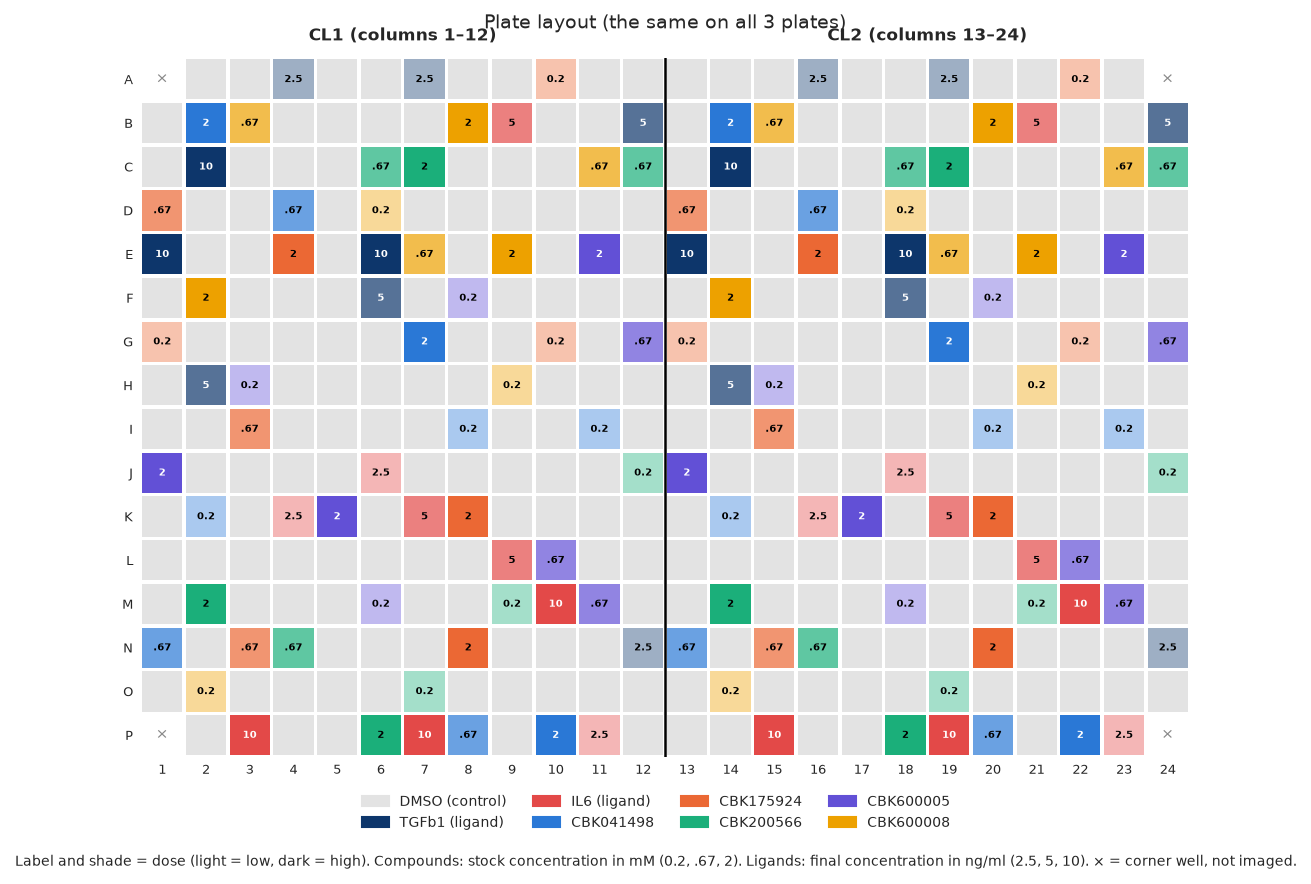

In [7]:
# figure: the plate layout, one square per well; color = agent, shade and label = dose
def dose_shade(color, level):
    """Mix the agent color with white: light for the low dose, full color for the high dose."""
    rgb = np.array(mcolors.to_rgb(color))
    return tuple(rgb + (1 - rgb) * [0.6, 0.3, 0.0][level])


def ink_for(face):
    """Black or white label, whichever reads better on this background."""
    r, g, b = mcolors.to_rgb(face)
    return "black" if 0.2126 * r + 0.7152 * g + 0.0722 * b > 0.45 else "white"


dose_short = {"0.2": "0.2", "0.67": ".67", "2.0": "2", "L": "2.5", "M": "5", "H": "10"}
fig, ax = plt.subplots(figsize=(7.2, 5.2), layout="constrained")
for w in layout.iter_rows(named=True):
    agent = w["Metadata_treatment"]
    if agent == "DMSO":
        face, label = agent_colors["DMSO"], ""
    else:
        face, label = dose_shade(agent_colors[agent], dose_level[w["dose"]]), dose_short[w["dose"]]
    ax.add_patch(Rectangle((w["col_idx"] - 0.46, w["row_idx"] - 0.46), 0.92, 0.92, facecolor=face, edgecolor="none"))
    ax.text(w["col_idx"], w["row_idx"], label, ha="center", va="center", fontsize=5, color=ink_for(face), fontweight="bold")
for r, c in [(0, 0), (0, 23), (15, 0), (15, 23)]:
    ax.text(c, r, "×", ha="center", va="center", fontsize=7, color="#888888")
ax.axvline(11.5, color="black", lw=1.2)
ax.set_xlim(-0.5, n_cols - 0.5)
ax.set_ylim(n_rows - 0.5, -0.5)
ax.set_aspect("equal")
ax.set_xticks(range(n_cols), labels=[str(i) for i in range(1, n_cols + 1)])
ax.set_yticks(range(n_rows), labels=plate_rows)
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
ax.text(5.5, -0.8, "CL1 (columns 1–12)", ha="center", va="bottom", fontsize=8, fontweight="bold")
ax.text(17.5, -0.8, "CL2 (columns 13–24)", ha="center", va="bottom", fontsize=8, fontweight="bold")
handles = [Patch(color=agent_colors["DMSO"], label="DMSO (control)")]
handles += [Patch(color=agent_colors[a], label=f"{a} (ligand)") for a in ["TGFb1", "IL6"]]
handles += [Patch(color=agent_colors[a], label=a) for a in compounds]
fig.legend(handles=handles, loc="lower center", ncols=4, bbox_to_anchor=(0.5, -0.07))
fig.text(
    0.5, -0.1,
    "Label and shade = dose (light = low, dark = high). Compounds: stock concentration in mM (0.2, .67, 2). "
    "Ligands: final concentration in ng/ml (2.5, 5, 10). × = corner well, not imaged.",
    ha="center", fontsize=6.5,
)
ax.set_title("Plate layout (the same on all 3 plates)", fontsize=9, pad=14)
save_fig(fig, "01_plate-layout_treatments-and-doses")

**Result: PASS.**

- All 3 plates use one layout. The plate map and the ligand file agree with the profiles in every well. The CL2 half repeats the CL1 half exactly, 12 columns to the right.
- Per cell line and plate, there are 127 DMSO wells and 3 wells for each of the 21 treatments (7 agents × 3 doses).
- Every well received 1,500 nL from the compound plate, so the DMSO amount is the same in all wells. The ligand doses come from different volumes (50, 100 and 200 nL). The 4 corner wells received DMSO, but the microscope did not image them.
- The replicate wells are spread over the plate. Per cell line, 30 of the 42 replicate sets use 3 different rows, and 34 use 3 different columns. The closest two wells of a set are a median of 4 wells apart.
- DMSO wells fill the rest of each half, including 62 of the 100 wells on its outer ring.
- **Limit of the layout:** each cell line always sits on the same half, and each treatment always sits in the same wells on all 3 plates. So a position effect looks the same on every plate. The data also cannot separate cell line from plate half.

## 3. Imaging

A SQUID microscope with a 20× objective imaged the plates. It imaged 9 fields of view per well (a 3 × 3 grid, 0.9 mm apart) in 5 channels. The image folders keep two records per plate:

- `parameters.json`: the settings of the plate.
- `coords.jsonl`: the position, focus height and time of every image.

**Pass if:** the microscope used the same settings on the 3 plates, and the focus height changes smoothly across the plate.

In [8]:
# microscope settings of each plate, for the 5 fluorescence channels
setting_rows, image_rows = [], []
for plate_dir in sorted(p for p in imaging_dir.iterdir() if p.is_dir()):
    files = plate_dir / "input" / plate_dir.name
    params = json.loads((files / "parameters.json").read_text())
    tp = plate_dir.name.split("_")[3]
    for ch in params["channels_config"]:
        nm = ch["Name"].split()[1]
        if nm in channel_stain:
            setting_rows.append({
                "time_point": tp, "imaging_started": params["timestamp"], "channel": f"{nm} nm", "stain": channel_stain[nm],
                "exposure_ms": ch["ExposureTime"], "gain": round(ch["AnalogGain"], 2), "light_pct": ch["IlluminationIntensity"],
                "focus_offset_um": ch["RelativeZOffsetUM"],
            })
    image_rows.append(pl.read_ndjson(files / "coords.jsonl").with_columns(time_point=pl.lit(tp)))
    print(f"{tp} plate: imaging started {params['timestamp']}, {params['objective']}, {params['microscope_name']}, plate {params['plate_type']}, {len(params['well_list'])} wells")
settings = pl.DataFrame(setting_rows).sort(pl.col("time_point").cast(pl.Enum(plate_order)), "stain")
settings.write_csv(table_dir / "imaging_settings.csv")
stain_order = ["DNA", "RNA", "ER", "AGP", "Mito"]
# settings that differ from the 1h plate
reference = settings.filter(pl.col("time_point") == "1h").drop("time_point", "imaging_started")
changed = []
for tp in plate_order[1:]:
    other = settings.filter(pl.col("time_point") == tp).drop("time_point", "imaging_started")
    for ref, oth in zip(reference.sort("stain").iter_rows(named=True), other.sort("stain").iter_rows(named=True)):
        for key in ["exposure_ms", "gain", "light_pct", "focus_offset_um"]:
            if ref[key] != oth[key]:
                changed.append(f"{tp} plate, {ref['stain']}: {key} {ref[key]:g} -> {oth[key]:g}")
print("settings that differ from the 1h plate:", "; ".join(changed) if changed else "none")

# one row per image: when it was taken (seconds after the plate started) and its focus height
images = pl.concat(image_rows).rename({"well": "Metadata_Well"})
per_well = (
    images.group_by("time_point", "Metadata_Well")
    .agg(
        minutes_after_start=pl.col("ts").min() / 60,
        focus_um=pl.col("z").filter(pl.col("channel").str.contains("405")).median(),
        focus_sd_um=pl.col("z").filter(pl.col("channel").str.contains("405")).std(),
    )
    .with_columns(focus_rel_um=pl.col("focus_um") - pl.col("focus_um").median().over("time_point"))
)
wells = wells.join(per_well, on=["time_point", "Metadata_Well"], how="left", maintain_order="left")
assert wells["minutes_after_start"].null_count() == 0
order = images.filter(pl.col("time_point") == "1h").group_by("Metadata_Well").agg(pl.col("ts").min()).sort("ts")["Metadata_Well"].to_list()
print(f"imaging order (1h plate): {', '.join(order[:4])} … {', '.join(order[20:26])} … {order[-1]}")
images.group_by("time_point").agg(
    images=pl.len(), fields_of_view=pl.struct("Metadata_Well", "site_x", "site_y").n_unique(), minutes=pl.col("ts").max() / 60,
).join(
    wells.group_by("time_point").agg(
        focus_range_um=pl.col("focus_rel_um").max() - pl.col("focus_rel_um").min(),
        median_focus_sd_within_well_um=pl.col("focus_sd_um").median(),
    ),
    on="time_point",
).with_columns(seconds_per_well=60 * pl.col("minutes") / 380).sort(pl.col("time_point").cast(pl.Enum(plate_order))).with_columns(pl.selectors.float().round(1))

1h plate: imaging started 2026-10-03_12.20.40, 20x (Olympus), HCS SQUID: squikon A, plate 384-PE-6057302, 380 wells
4h plate: imaging started 2026-10-05_14.52.02, 20x (Olympus), HCS SQUID: squikon A, plate 384-PE-6057302, 380 wells
24h plate: imaging started 2026-10-06_12.54.35, 20x (Olympus), HCS SQUID: squikon A, plate 384-PE-6057302, 380 wells
settings that differ from the 1h plate: 24h plate, AGP: exposure_ms 80 -> 90; 24h plate, ER: exposure_ms 100 -> 200; 24h plate, Mito: focus_offset_um -4.3 -> -7.15
imaging order (1h plate): A02, A03, A04, A05 … A22, A23, B24, B23, B22, B21 … P02


time_point,images,fields_of_view,minutes,focus_range_um,median_focus_sd_within_well_um,seconds_per_well
str,u32,u32,f64,f64,f64,f64
"""1h""",17100,3420,228.0,183.7,2.5,36.0
"""4h""",17100,3420,226.5,201.3,2.6,35.8
"""24h""",17100,3420,229.6,173.2,2.5,36.2


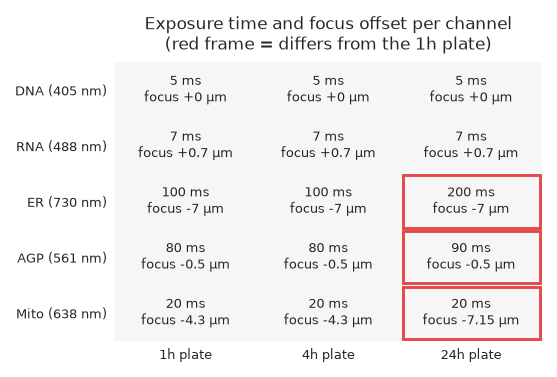

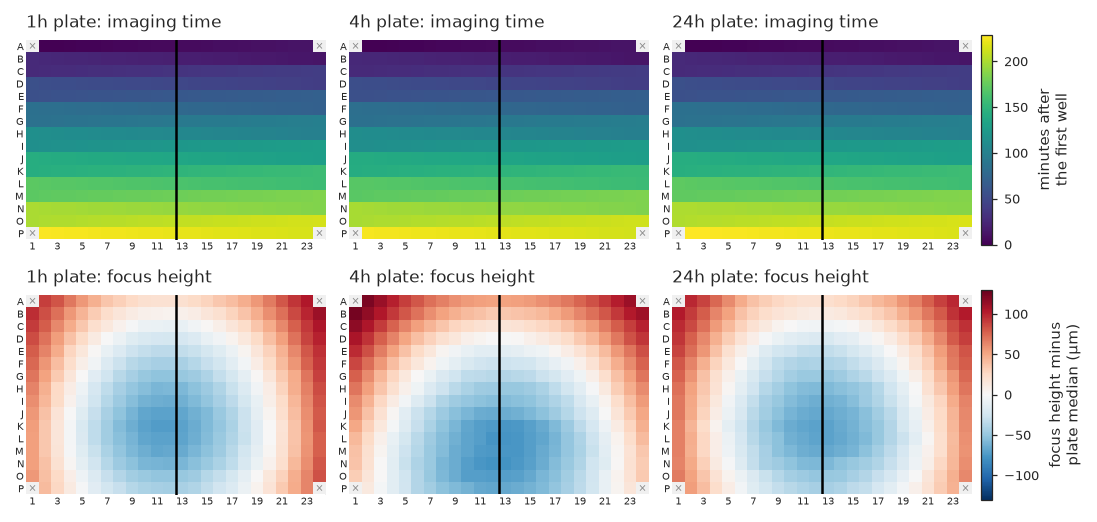

In [9]:
# figure: imaging settings per plate; a red frame marks a setting that differs from the 1h plate
fig, ax = plt.subplots(figsize=(3.6, 2.4), layout="constrained")
exp = np.array([[settings.filter((pl.col("stain") == s) & (pl.col("time_point") == tp))["exposure_ms"][0] for tp in plate_order] for s in stain_order])
off = np.array([[settings.filter((pl.col("stain") == s) & (pl.col("time_point") == tp))["focus_offset_um"][0] for tp in plate_order] for s in stain_order])
ax.imshow(np.zeros_like(exp), cmap=mcolors.ListedColormap(["#f6f6f6"]), aspect="auto")
for i, s in enumerate(stain_order):
    for j, tp in enumerate(plate_order):
        ax.text(j, i, f"{exp[i, j]:g} ms\nfocus {off[i, j]:+g} µm", ha="center", va="center", fontsize=6)
        if exp[i, j] != exp[i, 0] or off[i, j] != off[i, 0]:
            ax.add_patch(Rectangle((j - 0.48, i - 0.47), 0.96, 0.94, fill=False, edgecolor="#e34948", lw=1.4))
nm_of = {v: k for k, v in channel_stain.items()}
ax.set_xticks(range(len(plate_order)), labels=[f"{tp} plate" for tp in plate_order])
ax.set_yticks(range(len(stain_order)), labels=[f"{s} ({nm_of[s]} nm)" for s in stain_order])
ax.tick_params(length=0)
ax.spines[:].set_visible(False)
ax.set_title("Exposure time and focus offset per channel\n(red frame = differs from the 1h plate)")
save_fig(fig, "02_imaging-settings")

# figure: when each well was imaged, and the autofocus height, per plate
time_norm = Normalize(vmin=0, vmax=float(wells["minutes_after_start"].max()))
focus_lim = float(np.ceil(np.abs(wells["focus_rel_um"]).max() / 10) * 10)
fig, axes = plt.subplots(2, 3, figsize=(7.2, 3.4), layout="constrained")
for j, tp in enumerate(plate_order):
    plate = wells.filter(pl.col("time_point") == tp)
    im_t = draw_plate(axes[0, j], plate_array(plate, "minutes_after_start"), plt.get_cmap("viridis"), time_norm, f"{tp} plate: imaging time")
    im_z = draw_plate(axes[1, j], plate_array(plate, "focus_rel_um"), div_cmap, TwoSlopeNorm(0, -focus_lim, focus_lim), f"{tp} plate: focus height")
fig.colorbar(im_t, ax=axes[0, :], shrink=0.9, pad=0.01, label="minutes after\nthe first well")
fig.colorbar(im_z, ax=axes[1, :], shrink=0.9, pad=0.01, label="focus height minus\nplate median (µm)")
save_fig(fig, "03_plate-maps_imaging-time-and-focus")

**Result: WARN (settings differ on the 24h plate).**

- The same microscope and objective imaged all plates, on 3 different days (3, 5 and 6 October 2026).
- The 24h plate used 3 different settings. Its ER exposure was longer (200 vs 100 ms), its AGP exposure was longer (90 vs 80 ms), and its Mito focus offset was different (−7.15 vs −4.3 µm). The data cannot separate time point from these settings. So we compare wells only with the DMSO wells of the same plate.
- Each plate took about 228 minutes (36 s per well). The microscope moved row by row: row A from left to right, row B from right to left, and so on.
- In Cell Painting, the cells are fixed before staining. So the imaging time does not change the treatment time, but it can add technical drift. Notebook 01 tests this on the DMSO wells, and finds a top-to-bottom drift that follows the rows (= the imaging order).
- The focus height changes smoothly across each plate, like a shallow bowl. The edges are up to about 100 µm higher than the centre (range 173–201 µm). The 9 fields of view of a well differ by a median of only 2.5 µm.
- Neither the imaging order nor the focus follows the every-other-row pattern of CL1 at 1h and 4h (notebook 01).

## 4. Cell counts on the plates

Each square is one well, drawn where it sits on the plate. The black line splits the CL1 half (columns 1–12) from the CL2 half (columns 13–24).

- **Left:** all cells per well, relative to the DMSO wells of the same plate and cell line (log2 ratio). This removes the growth difference between the cell lines and plates, so only differences inside a plate remain. Small dots mark treated wells.
- **Right:** the share of cells in the well that pass QC.

The table below the maps splits the cells that fail QC into image QC and profile QC failures.

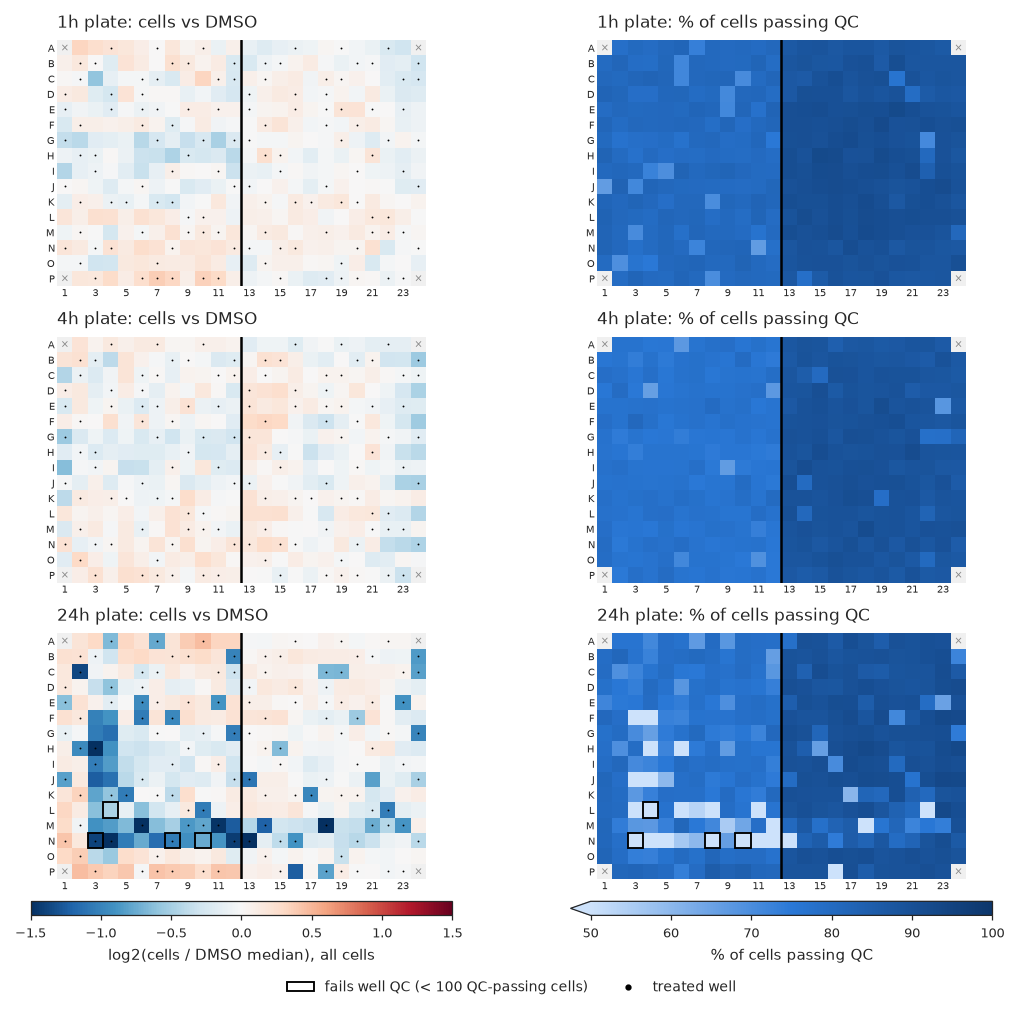

In [10]:
# cell count relative to the DMSO wells of the same plate and cell line
group_keys = ["Metadata_Plate", "cell_line"]
wells = wells.with_columns(
    dmso_median_all=pl.col("n_cells_all").filter(pl.col("is_dmso")).median().over(group_keys),
).with_columns(log2_ratio_all=(pl.col("n_cells_all") / pl.col("dmso_median_all")).log(2))

plates = {tp: wells.filter(pl.col("time_point") == tp) for tp in plate_order}
failed = {tp: plate_array(plates[tp].with_columns(f=(~pl.col("profile_ok")).cast(pl.Float64)), "f") == 1 for tp in plate_order}
ratio_lim = float(np.ceil(np.percentile(np.abs(wells["log2_ratio_all"]), 99.5) * 4) / 4)
ratio_norm = TwoSlopeNorm(vcenter=0, vmin=-ratio_lim, vmax=ratio_lim)
# most wells pass 70-95%, so the scale starts at 50 to show the differences (lower wells get the lightest color)
pass_norm = Normalize(vmin=50, vmax=100)

fig, axes = plt.subplots(3, 2, figsize=(7.2, 6.4), layout="constrained")
for i, tp in enumerate(plate_order):
    treated = plate_array(plates[tp].with_columns(t=(~pl.col("is_dmso")).cast(pl.Float64)), "t") == 1
    im_r = draw_plate(axes[i, 0], plate_array(plates[tp], "log2_ratio_all"), div_cmap, ratio_norm, f"{tp} plate: cells vs DMSO", treated=treated, flagged=failed[tp])
    im_p = draw_plate(axes[i, 1], plate_array(plates[tp], "pct_pass"), blues, pass_norm, f"{tp} plate: % of cells passing QC", flagged=failed[tp])
fig.colorbar(im_r, ax=axes[:, 0], location="bottom", shrink=0.8, aspect=30, pad=0.01, label="log2(cells / DMSO median), all cells")
fig.colorbar(im_p, ax=axes[:, 1], location="bottom", shrink=0.8, aspect=30, pad=0.01, label="% of cells passing QC", extend="min")
fig.legend(
    handles=[Patch(facecolor="none", edgecolor="black", lw=0.9, label="fails well QC (< 100 QC-passing cells)"),
             plt.Line2D([], [], marker="o", ls="", color="black", markersize=2, label="treated well")],
    loc="lower center", bbox_to_anchor=(0.5, -0.04), ncols=2,
)
save_fig(fig, "04_plate-maps_cell-count-and-qc")

In [11]:
# why cells fail QC: image QC (blurry or saturated image) vs profile QC (segmentation errors)
qc_summary = (
    wells.group_by("time_point", "cell_line")
    .agg(
        all_cells=pl.col("n_cells_all").sum(),
        fail_image=pl.col("n_fail_image").sum(),
        fail_profile=pl.col("n_fail_profile_only").sum(),
        qc_cells=pl.col("n_cells_qc").sum(),
        wells_below_9_images=(pl.col("n_sites_qc") < 9).sum(),
        median_pct_pass_per_well=pl.col("pct_pass").median(),
        min_pct_pass_per_well=pl.col("pct_pass").min(),
    )
    .with_columns(
        pct_pass=100 * pl.col("qc_cells") / pl.col("all_cells"),
        pct_fail_image=100 * pl.col("fail_image") / pl.col("all_cells"),
        pct_fail_profile=100 * pl.col("fail_profile") / pl.col("all_cells"),
    )
    .sort(pl.col("time_point").cast(pl.Enum(plate_order)), "cell_line")
)
qc_summary.write_csv(table_dir / "qc_pass_summary.csv")
qc_summary.select("time_point", "cell_line", "pct_pass", "pct_fail_image", "pct_fail_profile", "median_pct_pass_per_well", "min_pct_pass_per_well", "wells_below_9_images").with_columns(pl.selectors.float().round(1))

time_point,cell_line,pct_pass,pct_fail_image,pct_fail_profile,median_pct_pass_per_well,min_pct_pass_per_well,wells_below_9_images
str,str,f64,f64,f64,f64,f64,u32
"""1h""","""CL1""",79.5,1.1,19.4,80.3,66.4,20
"""1h""","""CL2""",88.9,0.5,10.6,89.4,70.8,8
"""4h""","""CL1""",76.4,0.4,23.2,76.6,65.7,6
"""4h""","""CL2""",87.9,0.6,11.5,88.4,67.9,11
"""24h""","""CL1""",73.1,5.4,21.5,76.8,3.2,31
"""24h""","""CL2""",87.3,1.4,11.3,89.0,15.0,23


**Result:**

- The 1h and 4h plates are even, with no clear patches.
- On the 24h plate, CL1 has a block of low-count wells in columns 3–4 (rows F–N) and along rows M–N. These wells drop to about a third of the DMSO median. The 4 wells that fail well QC (black frames) all sit in this area.
- CL2 at 24h is also lower in rows M–N, but less so.
- DMSO wells and treated wells in these areas are both low. So the cause is seeding or handling, not the treatments.
- CL1 loses more cells to QC than CL2 on every plate (73–79% pass vs 87–89%). Most of these cells fail profile QC (19–23% vs 11%).
- Image QC matters only for CL1 at 24h (5.4% of cells). It hits the same low-count area, where single wells keep as little as 3% of their cells.

## 5. DMSO control wells

The DMSO wells show how much the cell number varies without any treatment. We look at three things:

- **5a:** the spread of the DMSO wells (CV = standard deviation / mean, in %) and the growth from 1h to 24h.
- **5b:** why some CL1 DMSO wells at 24h keep so few QC-passing cells.
- **5c:** whether wells at the plate edge, or in certain rows or columns, have fewer cells.

**Pass if:** the DMSO wells of one plate and cell line have a CV below about 15%, and no strong edge or row/column pattern.

### 5a. Spread and growth

In [12]:
dmso = wells.filter(pl.col("is_dmso"))
dmso_summary = (
    dmso.unpivot(index=["time_point", "cell_line"], on=["n_cells_all", "n_cells_qc"], variable_name="count", value_name="cells")
    .with_columns(pl.col("count").replace({"n_cells_all": "all cells", "n_cells_qc": "QC-passing cells"}))
    .group_by("count", "time_point", "cell_line")
    .agg(
        n_wells=pl.len(),
        median=pl.col("cells").median(),
        q25=pl.col("cells").quantile(0.25),
        q75=pl.col("cells").quantile(0.75),
        min=pl.col("cells").min(),
        max=pl.col("cells").max(),
        cv_pct=100 * pl.col("cells").std() / pl.col("cells").mean(),
        # robust CV ignores a few outlier wells
        robust_cv_pct=100 * 1.4826 * (pl.col("cells") - pl.col("cells").median()).abs().median() / pl.col("cells").median(),
        wells_below_half_median=(pl.col("cells") < 0.5 * pl.col("cells").median()).sum(),
    )
    .sort("count", pl.col("time_point").cast(pl.Enum(plate_order)), "cell_line")
)
dmso_summary.write_csv(table_dir / "dmso_cell-count_summary.csv")
dmso_summary.with_columns(pl.selectors.float().round(1))

count,time_point,cell_line,n_wells,median,q25,q75,min,max,cv_pct,robust_cv_pct,wells_below_half_median
str,str,str,u32,f64,f64,f64,i64,i64,f64,f64,u32
"""QC-passing cells""","""1h""","""CL1""",127,1858.0,1656.0,2014.0,1247,2253,13.2,13.1,0
"""QC-passing cells""","""1h""","""CL2""",127,1641.0,1529.0,1722.0,1289,1954,7.9,8.2,0
"""QC-passing cells""","""4h""","""CL1""",127,1809.0,1643.0,1920.0,1175,2198,11.4,12.3,0
"""QC-passing cells""","""4h""","""CL2""",127,1930.0,1806.0,2054.0,1329,2402,11.5,9.5,0
"""QC-passing cells""","""24h""","""CL1""",127,1562.0,1210.0,1833.0,39,2333,39.8,29.5,20
"""QC-passing cells""","""24h""","""CL2""",127,3240.0,3037.0,3375.0,229,3710,14.0,7.6,2
"""all cells""","""1h""","""CL1""",127,2300.0,2107.0,2503.0,1528,2887,12.6,12.9,0
"""all cells""","""1h""","""CL2""",127,1840.0,1742.0,1926.0,1494,2149,7.0,7.2,0
"""all cells""","""4h""","""CL1""",127,2356.0,2150.0,2516.0,1516,2837,10.9,10.7,0


In [13]:
# growth from 1h to 24h, from the DMSO medians
dmso_summary.filter(pl.col("count") == "all cells").pivot(on="time_point", index="cell_line", values="median").with_columns(
    fold_24h_vs_1h=(pl.col("24h") / pl.col("1h")).round(2)
)

cell_line,1h,4h,24h,fold_24h_vs_1h
str,f64,f64,f64,f64
"""CL1""",2300.0,2356.0,2085.0,0.91
"""CL2""",1840.0,2187.0,3605.0,1.96


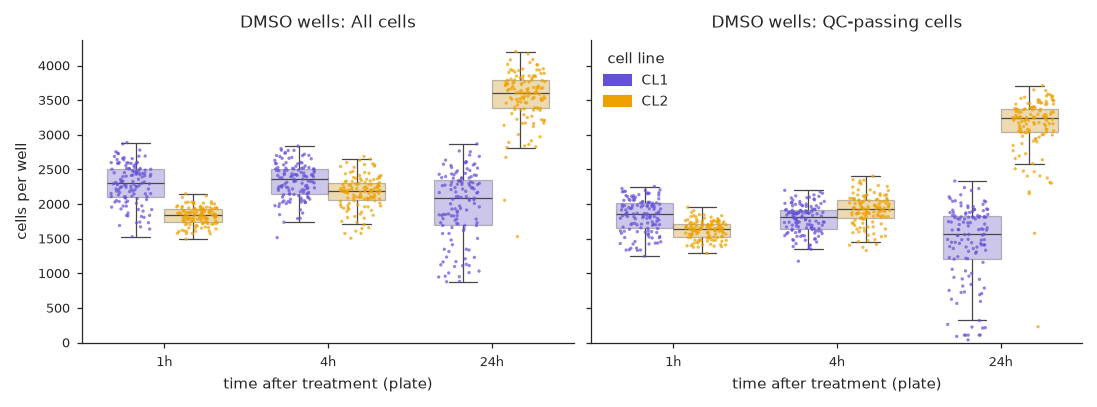

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.6), layout="constrained", sharey=True)
plot_df = dmso.select("time_point", "cell_line", "n_cells_all", "n_cells_qc").to_pandas()
for ax, (col, title) in zip(axes, [("n_cells_all", "All cells"), ("n_cells_qc", "QC-passing cells")]):
    sns.boxplot(
        data=plot_df, x="time_point", y=col, hue="cell_line", order=plate_order, hue_order=line_order,
        palette=line_colors, showfliers=False, width=0.7, boxprops={"alpha": 0.35}, linewidth=0.6, ax=ax, legend=False,
    )
    sns.stripplot(
        data=plot_df, x="time_point", y=col, hue="cell_line", order=plate_order, hue_order=line_order,
        palette=line_colors, dodge=True, size=1.6, alpha=0.7, jitter=0.25, ax=ax, legend=False,
    )
    ax.set_title(f"DMSO wells: {title}")
    ax.set_xlabel("time after treatment (plate)")
    ax.set_ylabel("cells per well")
    ax.set_ylim(bottom=0)
axes[1].legend(handles=[Patch(color=line_colors[l], label=l) for l in line_order], title="cell line", loc="upper left")
save_fig(fig, "05_dmso_cell-count-distribution")

**Result of 5a:**

- CL1 does not grow. The DMSO median is 2,300 (1h), 2,356 (4h) and 2,085 (24h) cells per well (0.91× from 1h to 24h). CL2 grows from 1,840 to 2,187 to 3,605 cells (1.96×).
- The spread passes on the 1h and 4h plates (CV 7–13%) and for CL2 at 24h (11%).
- The spread fails for CL1 at 24h: CV 25% for all cells and 40% for QC-passing cells. 8 DMSO wells hold fewer than half the median. Two of its DMSO wells (L04, N10) have fewer than 100 QC-passing cells and fail well QC.

### 5b. Why do some CL1 DMSO wells at 24h keep so few QC-passing cells?

In the right panel above, some CL1 DMSO wells at 24h keep almost no QC-passing cells. The images below show the 4 CL1 DMSO wells at 24h with the fewest QC-passing cells. For each well, we show the field of view that lost the most cells.

- **Top:** the DNA stain. A cyan outline marks a cell that passes QC, and a red outline marks a cell that QC removes.
- **Bottom:** the Mito stain of the same field. Yellow marks pixels at the camera's maximum. Image QC fails a field when more than 1% of the pixels of a channel are at the maximum.

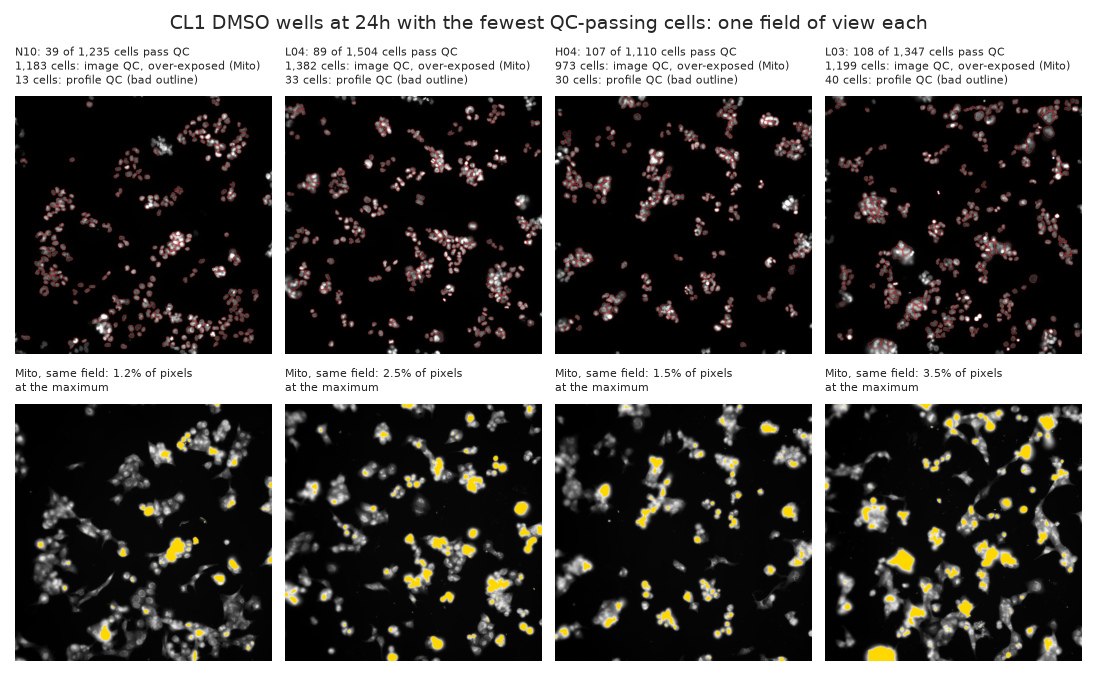

In [15]:
# Example images: the 4 CL1 DMSO wells at 24h with the fewest QC-passing cells (the dots near 0 in the right panel).
# For each well, we show the field of view that lost the most cells.
# Top: DNA stain, nucleus outline cyan = cell passes QC, red = cell removed by QC.
# Bottom: Mito stain of the same field, yellow = pixels at the camera's maximum (image QC fails a field when > 1% of a channel's pixels are at the maximum).
low_wells = dmso.filter((pl.col("time_point") == "24h") & (pl.col("cell_line") == "CL1")).sort("n_cells_qc").head(4)
plate = low_wells["Metadata_Plate"][0]
masks_dir = pathlib.Path((imaging_dir / plate / "DONE").read_text().strip()) / "masks" / plate
removed = (
    pl.scan_parquet(sc_qc_path)
    .select("Metadata_Plate", "Metadata_Well", "Metadata_Acquisition", "Metadata_ObjectNumber", "Metadata_image_qc",
            "Metadata_image_qc_reason", "Metadata_profile_qc", "Metadata_profile_qc_reason")
    .with_columns(pl.col(pl.Categorical).cast(pl.String))
    .filter((pl.col("Metadata_Plate") == plate) & pl.col("Metadata_Well").is_in(low_wells["Metadata_Well"].implode()))
    .collect()
    .with_columns(
        failed=(pl.col("Metadata_image_qc") == "fail") | (pl.col("Metadata_profile_qc") == "fail"),
        # image QC first: a failed image removes every cell in it
        reason=pl.when(pl.col("Metadata_image_qc") == "fail").then(pl.format("image QC, {}", "Metadata_image_qc_reason"))
        .when(pl.col("Metadata_profile_qc") == "fail").then(pl.lit("profile QC (bad outline)")),
    )
)


def scaled(image):
    """Grey image scaled between its 1st and 99.8th percentile."""
    low, high = np.percentile(image, [1, 99.8])
    return np.dstack([np.clip((image - low) / (high - low), 0, 1)] * 3)


fig, axes = plt.subplots(2, len(low_wells), figsize=(7.2, 4.4), layout="constrained")
for column, well in enumerate(low_wells.iter_rows(named=True)):
    in_well = removed.filter(pl.col("Metadata_Well") == well["Metadata_Well"])
    site = in_well.group_by("Metadata_Acquisition").agg(pl.col("failed").sum()).sort("failed", "Metadata_Acquisition", descending=[True, False])["Metadata_Acquisition"][0]
    in_site = in_well.filter(pl.col("Metadata_Acquisition") == site)
    dna = np.array(Image.open(images_dir / plate / f"{site}_Fluorescence_405_nm_Ex.tiff")).astype(float)
    mito = np.array(Image.open(images_dir / plate / f"{site}_Fluorescence_638_nm_Ex.tiff")).astype(float)
    nuclei = np.array(Image.open(masks_dir / f"{site}_Nuclei.tiff")).astype(int)

    top = scaled(dna)
    edges = (ndi.grey_dilation(nuclei, size=5) != ndi.grey_erosion(nuclei, size=5)) & (nuclei > 0)
    top[edges & np.isin(nuclei, in_site.filter(~pl.col("failed"))["Metadata_ObjectNumber"].to_numpy())] = (0, 0.9, 1)
    top[edges & np.isin(nuclei, in_site.filter(pl.col("failed"))["Metadata_ObjectNumber"].to_numpy())] = (1, 0.15, 0.15)
    bottom = scaled(mito)
    saturated = mito >= 0.99 * 65535
    bottom[ndi.binary_dilation(saturated, iterations=2)] = (1, 0.85, 0)

    reasons = in_well.filter(pl.col("failed"))["reason"].value_counts(sort=True)
    lines = "\n".join(f"{r['count']:,} cells: {r['reason']}" for r in reasons.head(2).iter_rows(named=True))
    axes[0, column].imshow(top)
    axes[0, column].set_title(f"{well['Metadata_Well']}: {well['n_cells_qc']:,} of {well['n_cells_all']:,} cells pass QC\n{lines}", fontsize=5.5, loc="left")
    axes[1, column].imshow(bottom)
    axes[1, column].set_title(f"Mito, same field: {100 * saturated.mean():.1f}% of pixels\nat the maximum", fontsize=5.5, loc="left")
    for ax in axes[:, column]:
        ax.axis("off")
fig.suptitle("CL1 DMSO wells at 24h with the fewest QC-passing cells: one field of view each")
save_fig(fig, "06_dmso_low-count-example-images")

**Result of 5b:** these wells hold about 1,100–1,500 cells, close to a normal count. QC removes most of them because their fields of view fail image QC: 1.2–3.5% of the Mito pixels are at the camera's maximum. Dense clumps of CL1 cells make the Mito image too bright. So the low QC-passing counts in these wells come from over-exposure, not from missing cells.

### 5c. Position effects

We compare the DMSO wells on the outer ring of the plate (row A or P, column 1 or 24) with the inner DMSO wells. We also list the row and the column with the lowest median count on each plate.

In [16]:
# edge wells = the outer ring of the plate (row A or P, column 1 or 24)
dmso = dmso.with_columns(
    position=pl.when(pl.col("Metadata_Row").is_in(["A", "P"]) | pl.col("col_idx").is_in([0, 23]))
    .then(pl.lit("edge"))
    .otherwise(pl.lit("inner"))
)
edge_rows = []
for (tp, line), grp in dmso.group_by("time_point", "cell_line"):
    edge = grp.filter(pl.col("position") == "edge")["log2_ratio_all"].to_numpy()
    inner = grp.filter(pl.col("position") == "inner")["log2_ratio_all"].to_numpy()
    edge_rows.append(
        {
            "time_point": tp, "cell_line": line, "n_edge": len(edge), "n_inner": len(inner),
            "edge_median_pct_of_dmso": 100 * 2 ** np.median(edge),
            "inner_median_pct_of_dmso": 100 * 2 ** np.median(inner),
            "mannwhitney_p": stats.mannwhitneyu(edge, inner).pvalue,
        }
    )
edge_table = pl.DataFrame(edge_rows).sort(pl.col("time_point").cast(pl.Enum(plate_order)), "cell_line")
edge_table.write_csv(table_dir / "dmso_edge-vs-inner.csv")
edge_table.with_columns(pl.col("edge_median_pct_of_dmso", "inner_median_pct_of_dmso").round(1), pl.col("mannwhitney_p").round(5))

time_point,cell_line,n_edge,n_inner,edge_median_pct_of_dmso,inner_median_pct_of_dmso,mannwhitney_p
str,str,i64,i64,f64,f64,f64
"""1h""","""CL1""",22,105,105.9,99.3,0.06607
"""1h""","""CL2""",22,105,94.6,100.7,0.00025
"""4h""","""CL1""",22,105,104.6,98.7,0.31415
"""4h""","""CL2""",22,105,95.0,100.9,0.00074
"""24h""","""CL1""",22,105,123.2,92.5,0.0
"""24h""","""CL2""",22,105,100.6,99.9,0.86844


In [17]:
# the lowest row and the lowest column of each plate and cell line (median % of DMSO, n = DMSO wells in it)
lowest = []
for name, index, label in [
    ("row", "row_idx", pl.col("row_idx").map_elements(plate_rows.__getitem__, return_dtype=pl.String)),
    ("column", "col_idx", (pl.col("col_idx") + 1).cast(pl.String)),
]:
    trend = dmso.group_by("time_point", "cell_line", index).agg(pl.col("log2_ratio_all").median(), n=pl.len())
    worst = trend.sort("log2_ratio_all").group_by("time_point", "cell_line", maintain_order=True).first()
    lowest.append(worst.select("time_point", "cell_line", pl.lit(name).alias("lowest"), label.alias("position"),
                               (100 * 2 ** pl.col("log2_ratio_all")).round(1).alias("pct_of_dmso"), "n"))
pl.concat(lowest).sort(pl.col("time_point").cast(pl.Enum(plate_order)), "cell_line", "lowest")

time_point,cell_line,lowest,position,pct_of_dmso,n
str,str,str,str,f64,u32
"""1h""","""CL1""","""column""","""4""",91.9,11
"""1h""","""CL1""","""row""","""H""",83.5,9
"""1h""","""CL2""","""column""","""23""",92.6,11
"""1h""","""CL2""","""row""","""A""",93.0,8
"""4h""","""CL1""","""column""","""1""",88.6,9
"""4h""","""CL1""","""row""","""G""",86.4,8
"""4h""","""CL2""","""column""","""23""",84.1,11
"""4h""","""CL2""","""row""","""B""",93.2,7
"""24h""","""CL1""","""column""","""4""",56.1,11


**Result of 5c:**

- CL1 at 24h: DMSO wells in row N have 54% of the median count, and DMSO wells in column 4 have 56%.
- On this plate, edge wells have *more* cells than inner wells (123% vs 92%, p < 0.001), because the low-count area lies inside the plate. So this is not a classic edge effect.
- Elsewhere, the position effects are small. CL2 edge wells at 1h and 4h have slightly fewer cells (95% vs 101%, p ≤ 0.001).
- Apart from the 24h plate (CL2 row M: 79%), no row or column falls below 83% of the median.

## Summary

**Data:** the layout files, the imaging records of the 3 plates, and 1,140 wells (3 plates × 2 cell lines × 190 wells, with 127 DMSO wells per cell line per plate). The wells hold 2.65 million cells, and 82.5% of them pass QC. 4 wells (all CL1, 24h plate) fail well QC, because they have fewer than 100 QC-passing cells.

**What we did:**

1. We drew the plate layout and checked it against the profiles.
2. We compared the imaging settings, imaging order and focus of the 3 plates.
3. We mapped the cell counts and QC pass rates of every well.
4. We measured the spread and the position effects of cell number in the DMSO wells.

**Findings:**

- All 3 plates use one layout, and CL2 repeats CL1 12 columns to the right. Per cell line and plate, there are 127 DMSO wells and 21 treatments × 3 wells, spread over the plate. The layout files agree with the profiles in every well.
- The 24h plate used a longer ER exposure (200 vs 100 ms), a longer AGP exposure (90 vs 80 ms) and a different Mito focus offset. Each plate took about 3.8 hours to image, row by row. The focus height changes smoothly.
- CL2 doubles from 1h to 24h (1,840 → 3,605 cells per DMSO well). CL1 does not grow (2,300 → 2,085).
- The 1h and 4h plates are even (DMSO CV 7–13%). On the 24h plate, CL1 has a low-count area (columns 3–4 rows F–N, and rows M–N), with row N at 54% of the median and a DMSO CV of 25%.
- This area also has the lowest share of cells that pass QC, and all 4 wells that fail well QC. In its emptiest DMSO wells, most cells sit in images that fail image QC because the Mito channel is over-exposed.

**Caveats:**

- The data cannot separate cell line from plate half (CL1 always in columns 1–12). They also cannot separate time point from exposure (the 24h plate used longer ER and AGP exposures). So all comparisons stay within one plate and one cell line.
- Doses are stock concentrations. The final well concentrations are unknown.

**Next:** notebook 01 tests how cell number and plate position change the profiles. Notebook 04 tests which treatments lower cell number.